In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install sklearn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd
df = pd.read_csv("C:/Users/User/Downloads/Order_delivery.csv")
print(df)

        Order_ID User_ID  Restaurant_ID  Driver_ID      Item_Name  Quantity  \
0              1   U3522            358        485  Fried Chicken         3   
1              2   U9214            316         65       Sandwich         3   
2              3   U7307            357        309        Koshary         3   
3              4   U3612            420         32          Sushi         2   
4              5   U3492             73        364        Koshary         5   
...          ...     ...            ...        ...            ...       ...   
99997      99998   U2735             12         88  Fried Chicken         4   
99998      99999   U7356            570        473        Koshary         4   
99999     100000   U3960            790        283        Koshary         5   
100000    100001   U5821            345        172         Burger         2   
100001    100002   U9147            621        391          Pizza         3   

        Total_Price        Order_Time     Delivery_

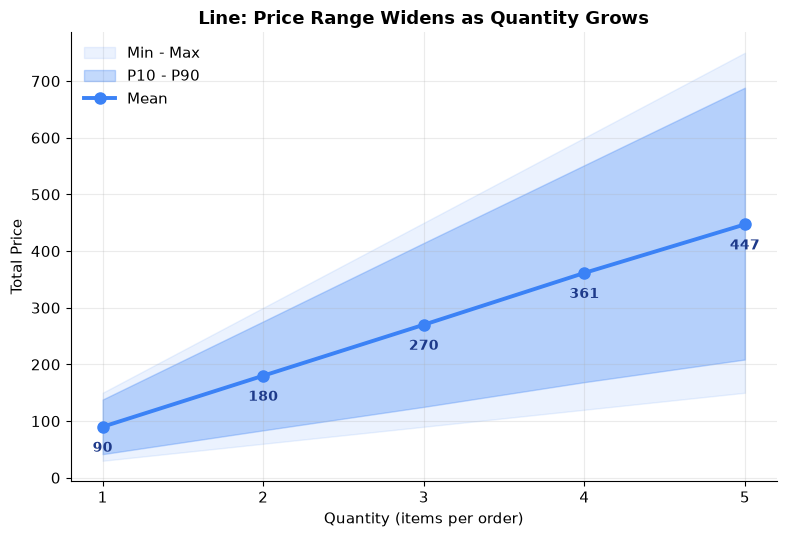

In [ ]:
#เมื่อสั่งอาหารจำนวนยชิ้นมากขึ้น(1-5ชิ้น)ราคาเฉลี่ยของออเดอร์
#เพิ่มขึ้นเป็นเท่าไหร่และกระจายตัวมากแค่ไหน

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]

# ---------- สรุปข้อมูลตามจำนวนชิ้น ----------
g = data.groupby("qty")["price"]
summary = pd.DataFrame({
    "mean": g.mean(), "p10": g.quantile(0.10), "p90": g.quantile(0.90),
    "min": g.min(), "max": g.max(),
}).reset_index()

# ---------- ธีม ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
BLUE = "#3b82f6"

# ---------- Line: ราคาเฉลี่ย + ช่วงราคาที่พบบ่อย (P10-P90) ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.fill_between(summary["qty"], summary["min"], summary["max"], color=BLUE, alpha=0.10, label="Min - Max")
ax.fill_between(summary["qty"], summary["p10"], summary["p90"], color=BLUE, alpha=0.30, label="P10 - P90")
ax.plot(summary["qty"], summary["mean"], marker="o", markersize=8, color=BLUE, linewidth=2.8, label="Mean")
for q, m in zip(summary["qty"], summary["mean"]):
    ax.annotate(f"{m:.0f}", (q, m), textcoords="offset points", xytext=(0, -18),
                ha="center", fontsize=10, color="#1e3a8a", fontweight="bold")
ax.set_xticks(summary["qty"])
ax.set_title("Line: Price Range Widens as Quantity Grows")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Total Price")
ax.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

จำนวนข้อมูล: 100,002 แถว | Correlation = 0.741


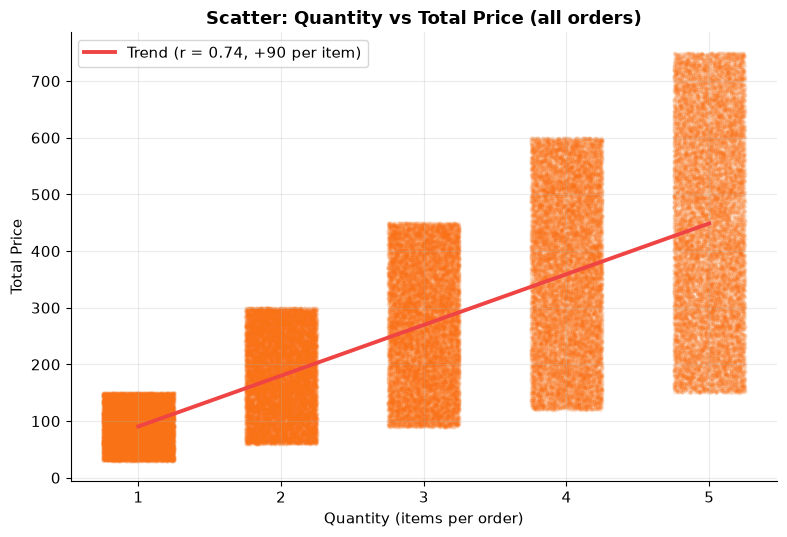

In [ ]:
#จำนวนชิ้นสินค้าที่สั่งกับราคารวมมีควาทมสัมพันธ์กันมากน้อยแค่ไหน
#และราคาเพิ่มขึ้นเฉลี่ยชิ้นละกี่บาท

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]
r = data["qty"].corr(data["price"])
print(f"จำนวนข้อมูล: {len(data):,} แถว | Correlation = {r:.3f}")

# ---------- ธีม ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
ORANGE, RED = "#f97316", "#ef4444"

# ---------- Scatter: ข้อมูลทั้งหมด + jitter + เส้นแนวโน้ม ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
rng = np.random.default_rng(42)
x_jit = data["qty"] + rng.uniform(-0.25, 0.25, len(data))
ax.scatter(x_jit, data["price"], s=4, alpha=0.08, color=ORANGE, rasterized=True)
slope, intercept = np.polyfit(data["qty"], data["price"], 1)
ax.plot([1, 5], [slope + intercept, 5 * slope + intercept], color=RED, linewidth=2.8,
        label=f"Trend (r = {r:.2f}, +{slope:.0f} per item)")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_title("Scatter: Quantity vs Total Price (all orders)")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Total Price")
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

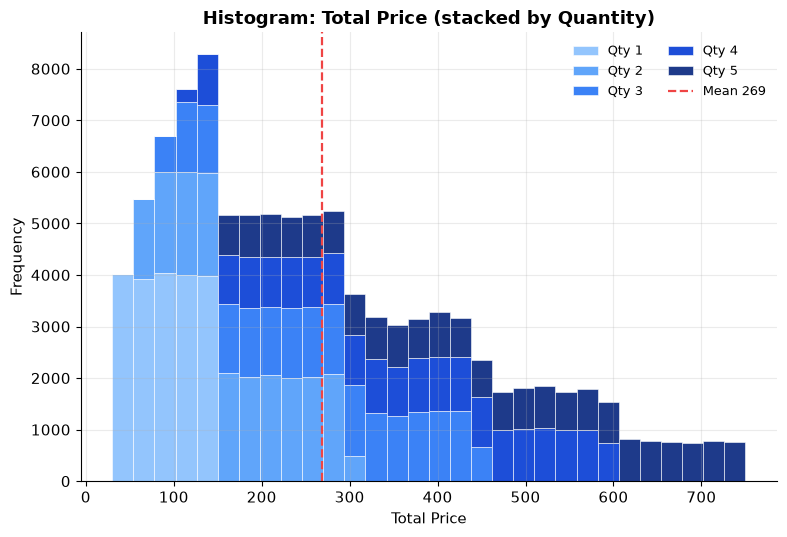

In [ ]:
#ราคารวมของออเดอร์เมื่อจำแนกตามระดับจำนวนสินค้าแต่ละกลุ่ม(1-5ชิ้น)
#มีรูปแบบการกระจายตัวอย่างไรและมีค่าเฉลี่ยแตกต่างกันอย่างไร

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]

# ---------- ธีม ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
RED = "#ef4444"
QCOLORS = ["#93c5fd", "#60a5fa", "#3b82f6", "#1d4ed8", "#1e3a8a"]   # สีของ Quantity 1-5

# ---------- Histogram: Total_Price แยกสีตาม Quantity (stacked) ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
groups = [data.loc[data["qty"] == q, "price"] for q in range(1, 6)]
ax.hist(groups, bins=30, stacked=True, color=QCOLORS, edgecolor="white", linewidth=0.4,
        label=[f"Qty {q}" for q in range(1, 6)])
ax.axvline(data["price"].mean(), color=RED, linestyle="--", linewidth=1.6,
           label=f"Mean {data['price'].mean():.0f}")
ax.set_title("Histogram: Total Price (stacked by Quantity)")
ax.set_xlabel("Total Price")
ax.set_ylabel("Frequency")
ax.legend(frameon=False, ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

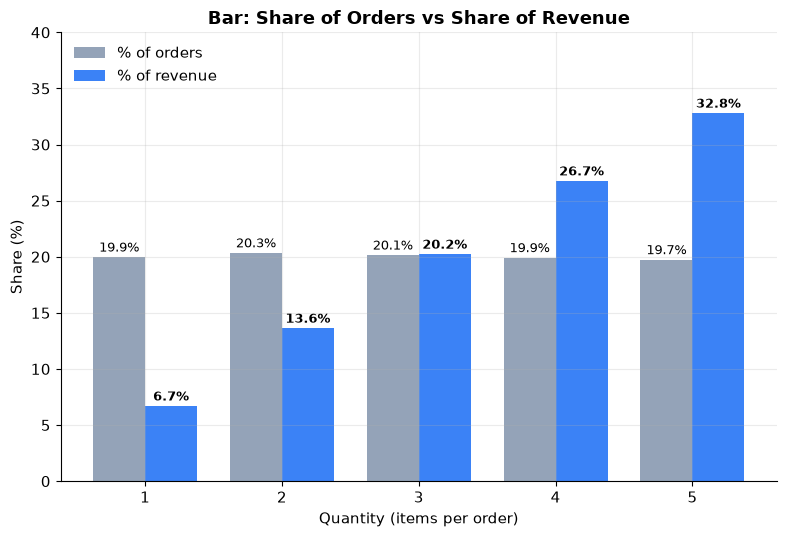

In [ ]:
#ลูกค้าสั่งออเดอร์แต่ละขนาดกี่เปอร์เซนต์และออเดอร์ขนาดกี่ชิ้นที่ทำรายได้รวมให้ร้านค้าได้มากที่สุด

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Order_delivery.csv"   # แก้ path ให้ตรงกับที่เก็บไฟล์

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH)
data = df[["Quantity", "Total_Price"]].copy()
data.columns = ["qty", "price"]

# ---------- สรุปข้อมูลตามจำนวนชิ้น ----------
g = data.groupby("qty")["price"]
summary = pd.DataFrame({"orders": g.size(), "revenue": g.sum()}).reset_index()
summary["order_share"] = summary["orders"] / summary["orders"].sum() * 100
summary["revenue_share"] = summary["revenue"] / summary["revenue"].sum() * 100

# ---------- ธีม ----------
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
BLUE = "#3b82f6"

# ---------- Bar: สัดส่วนจำนวนออเดอร์ vs สัดส่วนรายได้ ----------
fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(summary))
w = 0.38
b1 = ax.bar(x - w / 2, summary["order_share"], w, color="#94a3b8", label="% of orders")
b2 = ax.bar(x + w / 2, summary["revenue_share"], w, color=BLUE, label="% of revenue")
ax.bar_label(b1, fmt="%.1f%%", fontsize=9, padding=2)
ax.bar_label(b2, fmt="%.1f%%", fontsize=9, padding=2, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(summary["qty"])
ax.set_ylim(0, 40)
ax.set_title("Bar: Share of Orders vs Share of Revenue")
ax.set_xlabel("Quantity (items per order)")
ax.set_ylabel("Share (%)")
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
from pathlib import Path

df = pd.read_csv(r"C:/Users/MYASUS/Downloads/Order_delivery.csv")
TAB = Path("tables")
TAB.mkdir(exist_ok=True)

In [14]:
import pandas as pd
from pathlib import Path

df = pd.read_csv(r"C:/Users/MYASUS/Downloads/Order_delivery.csv")
TAB = Path("tables")
TAB.mkdir(exist_ok=True)

print(type(df)) 
df.head()

<class 'pandas.DataFrame'>


,Order_ID,User_ID,Restaurant_ID,Driver_ID,Item_Name,Quantity,Total_Price,Order_Time,Delivery_Time,Delivery_Duration_Minutes,...,Driver_Vehicle,Restaurant_Lat,Restaurant_Lon,Customer_Lat,Customer_Lon,Driver_Lat,Driver_Lon,Delivery_Distance_km,Traffic_Level,Driver_Availability
0,1,U3522,358,485,Fried Chicken,3,273.72,16-06-2025 08:32,16-06-2025 09:11,39,...,Motorbike,31.195082,29.921931,31.191404,29.904982,31.215658,29.910664,1.666106,High,Offline
1,2,U9214,316,65,Sandwich,3,365.82,03-06-2025 21:27,03-06-2025 22:00,33,...,Motorbike,30.605729,31.503079,30.586047,31.485820,30.580329,31.502380,2.738698,Low,Online
2,3,U7307,357,309,Koshary,3,401.94,01-06-2025 14:48,01-06-2025 15:26,38,...,Car,27.190180,31.177741,27.164869,31.169218,27.162976,31.189458,2.929079,Medium,Online
3,4,U3612,420,32,Sushi,2,221.18,13-06-2025 02:30,13-06-2025 03:22,52,...,Car,31.041846,31.381229,31.035773,31.380440,31.054690,31.401187,0.677498,Low,Online
4,5,U3492,73,364,Koshary,5,355.55,06-06-2025 09:48,06-06-2025 10:32,44,...,Motorbike,31.024141,31.376104,31.026023,31.396881,31.035350,31.389315,1.994769,High,Online
